# 04 · Negocio: alertas de rebalanceo para el día siguiente

**Decisión:** cada noche, marcar las estaciones-hora de mañana que tendrán un **pico** de salidas, para llevar bicicletas antes.

**Supuestos explícitos** (en `src/demanda_citibike/negocio.py`):

1. Un **pico** es una hora en que las salidas reales superan el percentil 90 de esa estación en el entrenamiento.
2. Una **alerta** es una estación-hora cuyo pronóstico supera ese umbral; cada alerta cuesta un viaje de camión.
3. Errores: **falsa alarma** (viaje en vano) y **pico perdido** (estación vacía, viajes no servidos).
4. Costo = falsas alarmas + *r* × picos perdidos. *r* no se puede estimar con estos datos (no hay costos de operación ni de viajes perdidos), así que se analiza la sensibilidad.

No se modela el inventario real de bicicletas por estación; es un ejercicio de decisión sobre el pronóstico, no un plan de rutas.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from demanda_citibike.config import PROCESADOS, REPORTES, FIGURAS

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#333333"
res = json.loads((REPORTES / "resultados.json").read_text(encoding="utf-8"))

In [2]:
neg = res["negocio"]
nombres = {"linea_base_estacional": "Base estacional", "dia_siguiente_media": "Día siguiente (media)",
           "dia_siguiente_p90": "Día siguiente (p90)", "una_hora_media": "1 hora (referencia, no disponible de noche)"}
tabla = pd.DataFrame(neg["estrategias"]).T.rename(index=nombres)
tabla

,alertas,picos_reales,aciertos,falsas_alarmas,picos_perdidos,precision_pct,recall_pct
Base estacional,3613.0,3075.0,845.0,2768.0,2230.0,23.4,27.5
Día siguiente (media),1601.0,3075.0,884.0,717.0,2191.0,55.2,28.7
Día siguiente (p90),5707.0,3075.0,1788.0,3919.0,1287.0,31.3,58.1
"1 hora (referencia, no disponible de noche)",1548.0,3075.0,1000.0,548.0,2075.0,64.6,32.5


Presentar la diferencia de falsas alarmas como "viajes de rebalanceo ahorrados" solo mira un lado: con la predicción media el modelo emite **menos alertas** y por eso tiene pocas falsas alarmas, pero deja pasar la mayoría de los picos (recall bajo). La comparación honesta pone los dos errores en la misma balanza.

In [3]:
costos = pd.DataFrame(neg["costo_por_razon"]).T.rename(columns=nombres)
costos.index = [f"r = {r}" for r in costos.index]
costos["más barata"] = [nombres[v] for v in neg["estrategia_mas_barata_por_razon"].values()]
costos

,Base estacional,Día siguiente (media),Día siguiente (p90),"1 hora (referencia, no disponible de noche)",más barata
r = 1,4998,2908,5206,2623,"1 hora (referencia, no disponible de noche)"
r = 2,7228,5099,6493,4698,"1 hora (referencia, no disponible de noche)"
r = 5,13918,11672,10354,10923,Día siguiente (p90)
r = 10,25068,22627,16789,21298,Día siguiente (p90)


In [4]:
print("Frente a la base estacional:")
for k, v in neg["frente_a_referencia"].items():
    print(f"  {nombres[k]:<45} falsas alarmas evitadas {v['falsas_alarmas_evitadas']:>6,} · picos perdidos evitados {v['picos_perdidos_evitados']:>6,} · domina: {v['domina_a_la_referencia']}")
print()
print("Razón r a partir de la cual alertar con p90 cuesta menos que alertar con la media:", neg["razon_equilibrio_p90_vs_media"])

Frente a la base estacional:
  Día siguiente (media)                         falsas alarmas evitadas  2,051 · picos perdidos evitados     39 · domina: True
  Día siguiente (p90)                           falsas alarmas evitadas -1,151 · picos perdidos evitados    943 · domina: False
  1 hora (referencia, no disponible de noche)   falsas alarmas evitadas  2,220 · picos perdidos evitados    155 · domina: True

Razón r a partir de la cual alertar con p90 cuesta menos que alertar con la media: 3.54


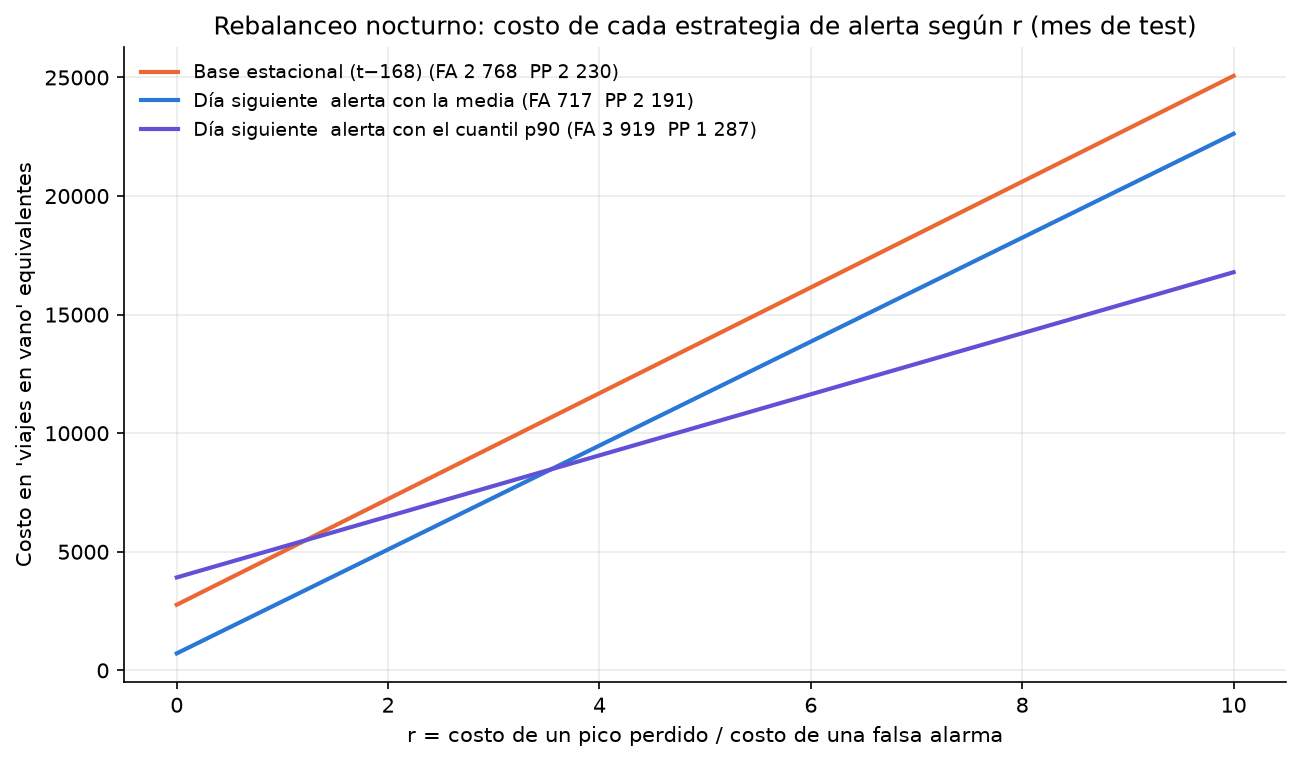

In [5]:
from IPython.display import Image
Image(filename=str(FIGURAS / "07_rebalanceo_costos.png"))

## Curva de umbral: de pocas alertas precisas a muchas alertas con más cobertura

En vez de fijar la regla, se puede mover el umbral de alerta (pronóstico > *k* × umbral del pico) y elegir *k* según el costo relativo. Los umbrales se recalculan aquí con los datos de entrenamiento, igual que en el pipeline.

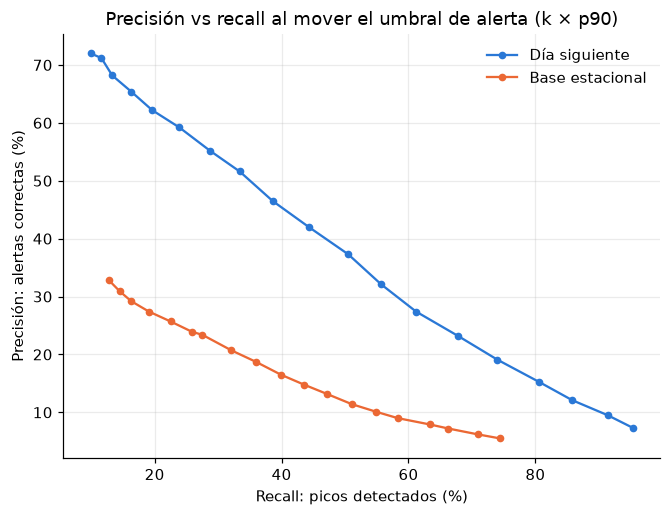

Picos reales en el test: 3,075 de 168,250 horas-estación (1.8 %)
Control k = 1: coincide con reports/resultados.json


In [6]:
from demanda_citibike.negocio import calcular_umbrales
demanda = pd.read_parquet(PROCESADOS / "demanda_horaria.parquet")
ini_test = pd.Timestamp(res["datos"]["test_final_desde"])
umbrales = calcular_umbrales(demanda[(demanda["fecha_hora"] < ini_test) & (demanda["fecha_hora"] >= "2024-01-15")])
pred = pd.read_parquet(REPORTES / "predicciones_test.parquet")
u = pred["estacion"].map(umbrales).to_numpy()
pico = pred["salidas"].to_numpy() > u
filas = []
for k in np.round(np.arange(0.4, 1.31, 0.05), 2):
    for col, nombre in [("pred_dia", "Día siguiente"), ("base_estacional", "Base estacional")]:
        alerta = pred[col].to_numpy() > k * u
        tp, fp, fn = (alerta & pico).sum(), (alerta & ~pico).sum(), (~alerta & pico).sum()
        filas.append({"k": k, "estrategia": nombre, "alertas": int(alerta.sum()), "falsas_alarmas": int(fp), "picos_perdidos": int(fn),
                      "precision_pct": round(tp / max(tp + fp, 1) * 100, 1), "recall_pct": round(tp / max(tp + fn, 1) * 100, 1)})
curva = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, color in [("Día siguiente", AZUL), ("Base estacional", NARANJA)]:
    c = curva[curva["estrategia"] == nombre]
    ax.plot(c["recall_pct"], c["precision_pct"], marker="o", markersize=4, color=color, label=nombre)
ax.set_xlabel("Recall: picos detectados (%)"); ax.set_ylabel("Precisión: alertas correctas (%)")
ax.set_title("Precisión vs recall al mover el umbral de alerta (k × p90)")
ax.legend(frameon=False)
plt.show()
print(f"Picos reales en el test: {pico.sum():,} de {len(pico):,} horas-estación ({pico.mean() * 100:.1f} %)")
# Control: con k = 1 se reproducen exactamente las cifras del pipeline.
k1 = curva[(curva["k"] == 1.0) & (curva["estrategia"] == "Día siguiente")].iloc[0]
assert k1["falsas_alarmas"] == neg["estrategias"]["dia_siguiente_media"]["falsas_alarmas"]
assert k1["picos_perdidos"] == neg["estrategias"]["dia_siguiente_media"]["picos_perdidos"]
print("Control k = 1: coincide con reports/resultados.json")

In [7]:
# Para cada r, el k de menor costo con cada estrategia
mejores = []
for r in [1, 2, 5, 10]:
    curva["costo"] = curva["falsas_alarmas"] + r * curva["picos_perdidos"]
    for nombre, g in curva.groupby("estrategia"):
        f = g.loc[g["costo"].idxmin()]
        mejores.append({"r": r, "estrategia": nombre, "k_optimo": f["k"], "costo": int(f["costo"]),
                        "precision_pct": f["precision_pct"], "recall_pct": f["recall_pct"]})
pd.DataFrame(mejores).pivot(index="r", columns="estrategia", values=["k_optimo", "costo", "recall_pct"])

k_optimo                         costo                    recall_pct              
estrategia Base estacional Día siguiente Base estacional Día siguiente Base estacional Día siguiente
r                                                                                                   
1                      1.3          1.10          3491.0        2839.0            12.8          19.6
2                      1.3          0.95          6171.0        5059.0            12.8          33.4
5                      1.0          0.80         13918.0       10220.0            27.5          50.5
10                     0.9          0.65         24494.0       16803.0            36.0          67.8

**Lectura para el negocio.**

* La curva precisión–recall del modelo día siguiente queda por encima de la de la base en todo el rango: a igual proporción de picos detectados, genera muchas menos falsas alarmas. Con el umbral óptimo para cada *r*, el modelo cuesta menos que la base para todos los *r* probados.
* El umbral óptimo depende de *r*. Si una falsa alarma y un pico perdido cuestan lo mismo (*r* = 1), conviene ser **más** exigente que el p90 (k = 1,10). Si un pico perdido cuesta 5 o 10 veces más, conviene bajar el umbral (k = 0,80 y 0,65) y aceptar más viajes para detectar entre la mitad y dos tercios de los picos. La regla fija "media > p90" (k = 1) solo es razonable para *r* cercano a 2.
* Como el modelo tiende a la media (notebook 03), con la regla fija la mayoría de los picos se quedan por debajo del umbral: ese es el motivo del recall bajo, no un fallo del umbral de pico.
* Los costos están en "viajes en vano equivalentes" y dependen de *r*, que el operador debe fijar con sus datos (costo por viaje de camión, ingreso perdido por estación vacía). Sin esos datos no se puede dar una cifra de ahorro en dinero.